# Car Price Prediction with Machine Learning

**Internship:** Oasis Infobyte  
**Domain:** Data Science  
**Task:** Task 3 – Car Price Prediction  
**Author:** Noor Afshan

## 1. Introduction

The price of a used car depends on several factors, such as its brand, manufacturing year, kilometres driven, fuel type and transmission.

In this project, I will use Python and Machine Learning techniques to analyse used car data and build models that can predict car selling prices.

## 2. Objectives

- Understand and clean the car price dataset.
- Explore factors that influence car prices.
- Perform exploratory data analysis (EDA).
- Build and compare regression models.
- Evaluate model performance using MAE, RMSE and R².
- Identify important features affecting car prices.

## 3. Tools and Libraries

- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

## 4. Project Workflow

1. Dataset loading and inspection
2. Data cleaning and preprocessing
3. Feature engineering
4. Exploratory Data Analysis
5. Data visualization
6. Machine Learning model building
7. Model evaluation
8. Results and conclusion

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("datasets/CAR DETAILS FROM CAR DEKHO.csv")

df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (4340, 8)

Column Names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Total Missing Values:
0

Duplicate Records:
763


In [6]:
duplicate_rows = df[df.duplicated()]

print("Duplicate Rows:")
duplicate_rows.head()

Duplicate Rows:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
13,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
14,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
15,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
16,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
17,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [7]:
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

print("Remaining Duplicates:", df.duplicated().sum())

Dataset Shape After Removing Duplicates: (3577, 8)
Remaining Duplicates: 0


In [8]:
df.describe()

,year,selling_price,km_driven
count,3577.000000,3.577000e+03,3577.000000
mean,2012.962538,4.739125e+05,69250.545709
std,4.251759,5.093018e+05,47579.940016
min,1992.000000,2.000000e+04,1.000000
25%,2010.000000,2.000000e+05,36000.000000
50%,2013.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [9]:
categorical_columns = [
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

for col in categorical_columns:
    print("\n", col.upper())
    print(df[col].value_counts())


 FUEL
fuel
Diesel      1800
Petrol      1717
CNG           37
LPG           22
Electric       1
Name: count, dtype: int64

 SELLER_TYPE
seller_type
Individual          2832
Dealer               712
Trustmark Dealer      33
Name: count, dtype: int64

 TRANSMISSION
transmission
Manual       3265
Automatic     312
Name: count, dtype: int64

 OWNER
owner
First Owner             2218
Second Owner             978
Third Owner              289
Fourth & Above Owner      75
Test Drive Car            17
Name: count, dtype: int64


In [10]:
current_year = 2026

df["car_age"] = current_year - df["year"]

df[["name", "year", "car_age"]].head()

,name,year,car_age
0,Maruti 800 AC,2007,19
1,Maruti Wagon R LXI Minor,2007,19
2,Hyundai Verna 1.6 SX,2012,14
3,Datsun RediGO T Option,2017,9
4,Honda Amaze VX i-DTEC,2014,12


SELLING PRICE ANALYSIS
Average Price: 473912.54207436397
Median Price: 350000.0
Minimum Price: 20000
Maximum Price: 8900000
Most Common Price: 300000

Skewness: 5.453918181903924
Distribution: Right-Skewed


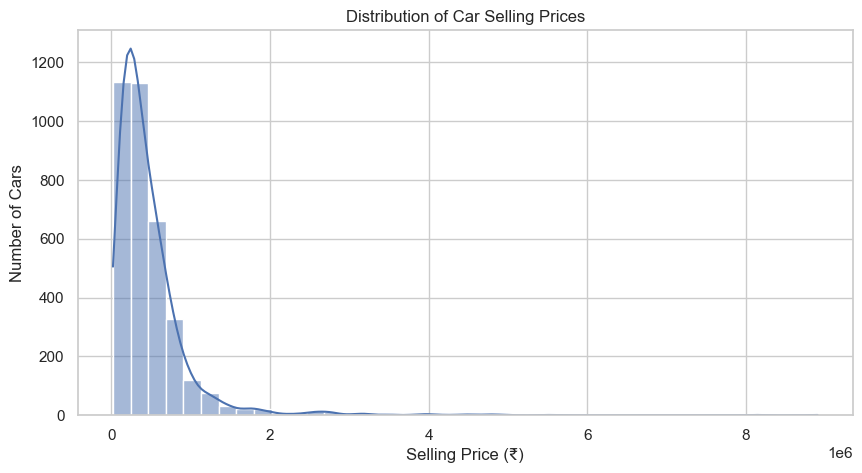

In [26]:
# Statistical Analysis
print("SELLING PRICE ANALYSIS")

print("Average Price:", df["selling_price"].mean())
print("Median Price:", df["selling_price"].median())
print("Minimum Price:", df["selling_price"].min())
print("Maximum Price:", df["selling_price"].max())
print("Most Common Price:", df["selling_price"].mode()[0])

# Skewness
skewness = df["selling_price"].skew()

print("\nSkewness:", skewness)

if skewness > 0:
    print("Distribution: Right-Skewed")
elif skewness < 0:
    print("Distribution: Left-Skewed")
else:
    print("Distribution: Approximately Symmetrical")

plt.figure(figsize=(10, 5))

sns.histplot(
    df["selling_price"],
    bins=40,
    kde=True
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Number of Cars")

plt.savefig("images/01_selling_price_distribution.png", bbox_inches="tight")
plt.show()

### Observation – Selling Price Distribution

1. The average selling price is approximately ₹4.74 lakh.
2. The median selling price is ₹3.50 lakh.
3. The most common selling price is ₹3 lakh.
4. The selling price distribution is highly right-skewed, with a skewness value of 5.45.
5. This indicates that most cars are concentrated in lower price ranges, while a few cars have considerably higher prices.

CORRELATION ANALYSIS
Correlation: -0.42426008154269546
Negative relationship: Older cars generally have lower selling prices.


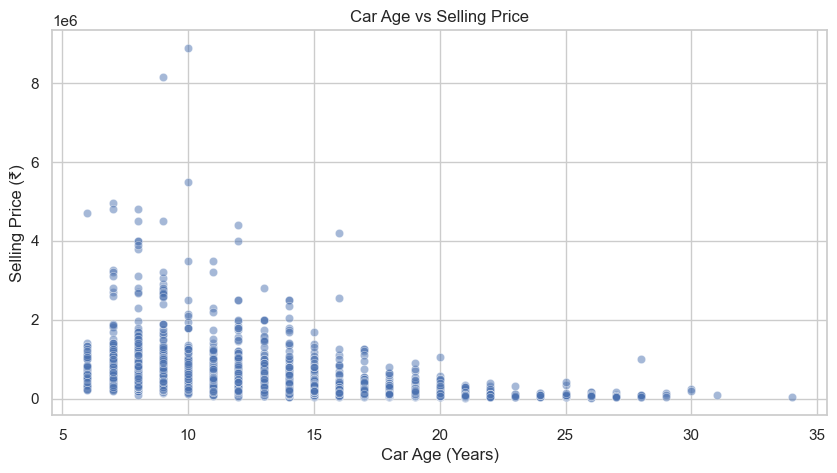

In [27]:
print("CORRELATION ANALYSIS")
correlation = df["car_age"].corr(df["selling_price"])

print("Correlation:", correlation)

if correlation < 0:
    print("Negative relationship: Older cars generally have lower selling prices.")
elif correlation > 0:
    print("Positive relationship: Older cars generally have higher selling prices.")
else:
    print("No linear relationship.")

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="car_age",
    y="selling_price",
    alpha=0.5
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (₹)")

plt.savefig("images/02_car_age_vs_price.png", bbox_inches="tight")
plt.show()

### Observation – Car Age vs Selling Price

1. The correlation between car age and selling price is approximately -0.42.
2. This indicates a moderate negative relationship.
3. Older cars generally have lower selling prices compared to newer cars.
4. Car age is an important feature that may help predict the selling price.

KILOMETRES DRIVEN ANALYSIS
Correlation: -0.42426008154269546
Negative relationship: Cars driven more kilometres generally have lower selling prices.


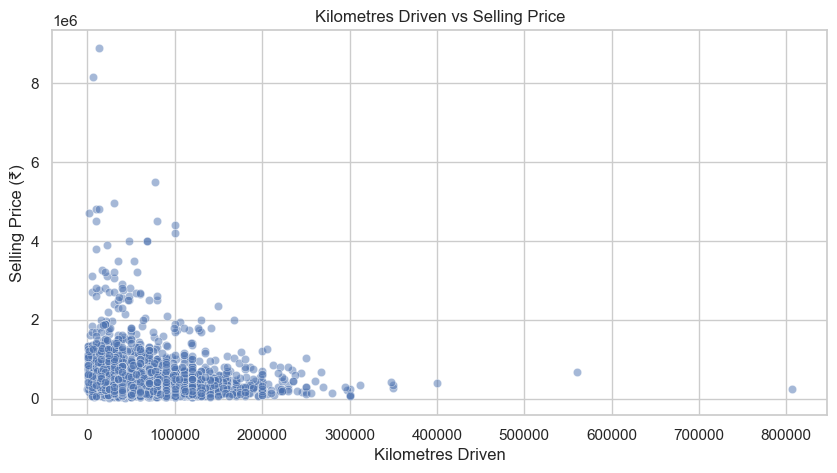

In [28]:
print("KILOMETRES DRIVEN ANALYSIS")
print("Correlation:", correlation)

if correlation < 0:
    print("Negative relationship: Cars driven more kilometres generally have lower selling prices.")
elif correlation > 0:
    print("Positive relationship: Cars driven more kilometres generally have higher selling prices.")
else:
    print("No linear relationship.")

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="km_driven",
    y="selling_price",
    alpha=0.5
)

plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price (₹)")

plt.savefig("images/03_km_driven_vs_price.png", bbox_inches="tight")
plt.show()

correlation = df["km_driven"].corr(df["selling_price"])

### Observation – Kilometres Driven vs Selling Price

1. The correlation between kilometres driven and selling price is approximately -0.19.
2. This indicates a weak negative relationship.
3. Cars driven for more kilometres generally tend to have lower selling prices.
4. However, kilometres driven alone may not strongly explain the variation in selling prices.

AVERAGE SELLING PRICE BY FUEL TYPE
fuel
Diesel      614001.07
Petrol      335344.34
Electric    310000.00
CNG         273162.08
LPG         171818.14
Name: selling_price, dtype: float64


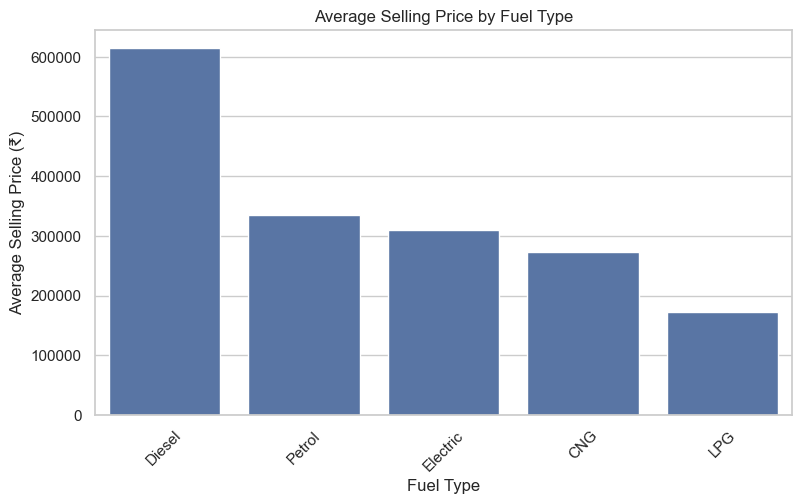

In [29]:
fuel_price = df.groupby("fuel")["selling_price"].mean().sort_values(ascending=False)

print("AVERAGE SELLING PRICE BY FUEL TYPE")
print(fuel_price.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(x=fuel_price.index, y=fuel_price.values)

plt.title("Average Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average Selling Price (₹)")
plt.xticks(rotation=45)

plt.savefig("images/04_fuel_type_vs_price.png", bbox_inches="tight")
plt.show()

### Observation – Average Selling Price by Fuel Type

1. Diesel cars have the highest average selling price of approximately ₹6.14 lakh.
2. Petrol cars have an average selling price of approximately ₹3.35 lakh.
3. LPG cars have the lowest average selling price of approximately ₹1.72 lakh.
4. The dataset contains only one electric car, so its average price is not representative.
5. Fuel type may help explain differences in car selling prices.

AVERAGE SELLING PRICE BY TRANSMISSION
transmission
Automatic    1274955.11
Manual        397365.75
Name: selling_price, dtype: float64


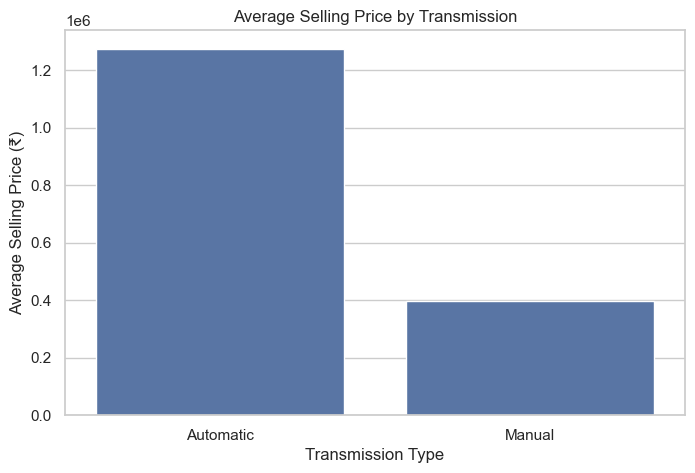

In [30]:
transmission_price = (
    df.groupby("transmission")["selling_price"]
    .mean()
    .sort_values(ascending=False)
)

print("AVERAGE SELLING PRICE BY TRANSMISSION")
print(transmission_price.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(
    x=transmission_price.index,
    y=transmission_price.values
)

plt.title("Average Selling Price by Transmission")
plt.xlabel("Transmission Type")
plt.ylabel("Average Selling Price (₹)")

plt.savefig("images/05_transmission_vs_price.png", bbox_inches="tight")
plt.show()

### Observation – Average Selling Price by Transmission

1. Automatic cars have an average selling price of approximately ₹12.75 lakh.
2. Manual cars have an average selling price of approximately ₹3.97 lakh.
3. Automatic cars show a considerably higher average selling price in this dataset.
4. Other factors, such as brand, model, and car age, may also contribute to this difference.
5. Transmission type may be useful for predicting car selling prices.

AVERAGE SELLING PRICE BY SELLER TYPE
seller_type
Trustmark Dealer    822272.73
Dealer              652699.39
Individual          424904.02
Name: selling_price, dtype: float64


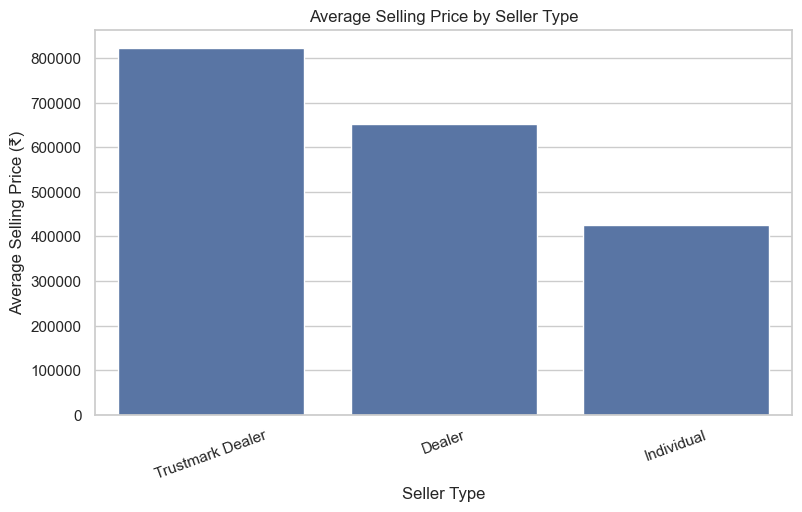

In [31]:
seller_price = (
    df.groupby("seller_type")["selling_price"]
    .mean()
    .sort_values(ascending=False)
)

print("AVERAGE SELLING PRICE BY SELLER TYPE")
print(seller_price.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    x=seller_price.index,
    y=seller_price.values
)

plt.title("Average Selling Price by Seller Type")
plt.xlabel("Seller Type")
plt.ylabel("Average Selling Price (₹)")
plt.xticks(rotation=20)

plt.savefig("images/06_seller_type_vs_price.png", bbox_inches="tight")
plt.show()

### Observation – Average Selling Price by Seller Type

1. Trustmark Dealers have the highest average selling price of approximately ₹8.22 lakh.
2. Dealers have an average selling price of approximately ₹6.53 lakh.
3. Individual sellers have the lowest average selling price of approximately ₹4.25 lakh.
4. Seller type may be a useful feature for predicting car selling prices.

AVERAGE SELLING PRICE BY OWNER TYPE
owner
Test Drive Car          954293.94
First Owner             565385.45
Second Owner            341954.14
Third Owner             266142.21
Fourth & Above Owner    181213.29
Name: selling_price, dtype: float64


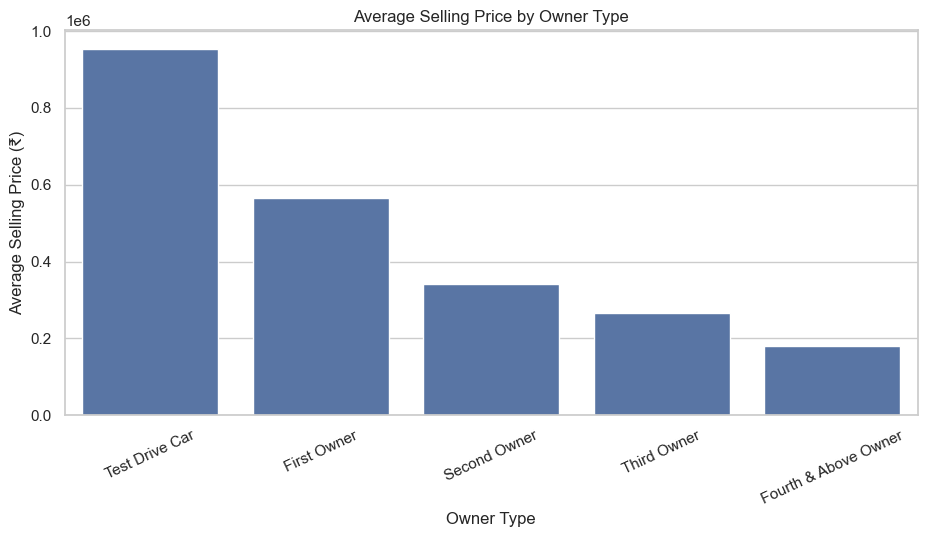

In [32]:
owner_price = (
    df.groupby("owner")["selling_price"]
    .mean()
    .sort_values(ascending=False)
)

print("AVERAGE SELLING PRICE BY OWNER TYPE")
print(owner_price.round(2))

plt.figure(figsize=(11, 5))
sns.barplot(
    x=owner_price.index,
    y=owner_price.values
)

plt.title("Average Selling Price by Owner Type")
plt.xlabel("Owner Type")
plt.ylabel("Average Selling Price (₹)")
plt.xticks(rotation=25)

plt.savefig("images/07_owner_type_vs_price.png", bbox_inches="tight")
plt.show()

### Observation – Average Selling Price by Owner Type

1. Test Drive Cars have the highest average selling price of approximately ₹9.54 lakh.
2. First-owner cars have an average selling price of approximately ₹5.65 lakh.
3. Second-owner, third-owner, and fourth-or-more-owner cars show progressively lower average prices.
4. This suggests that ownership history may influence car selling prices.
5. Owner type can be considered an important feature for price prediction.

In [22]:
# Extract the first word from the car name as its brand
df["brand"] = df["name"].str.split().str[0]

print("NUMBER OF UNIQUE CAR BRANDS:")
print(df["brand"].nunique())

print("\nTOP 10 CAR BRANDS BY NUMBER OF CARS:")
print(df["brand"].value_counts().head(10))

NUMBER OF UNIQUE CAR BRANDS:
29

TOP 10 CAR BRANDS BY NUMBER OF CARS:
brand
Maruti        1072
Hyundai        637
Mahindra       328
Tata           308
Ford           220
Honda          216
Toyota         170
Chevrolet      151
Renault        110
Volkswagen      93
Name: count, dtype: int64


### Observation – Car Brand Distribution

1. The dataset contains 29 unique car brands.
2. Maruti is the most frequently occurring brand, with 1,072 cars.
3. Hyundai ranks second, with 637 cars.
4. Mahindra and Tata are also among the most frequently occurring brands.
5. The dataset contains different numbers of cars for each brand.

TOP 10 BRANDS BY AVERAGE SELLING PRICE
brand
Land             3609800.00
Volvo            2556250.00
Mercedes-Benz    2299238.10
BMW              2242800.00
Audi             2185451.61
Jaguar           2072999.80
MG               1842500.00
Jeep             1530000.00
Isuzu            1500000.00
Kia              1300000.00
Name: selling_price, dtype: float64


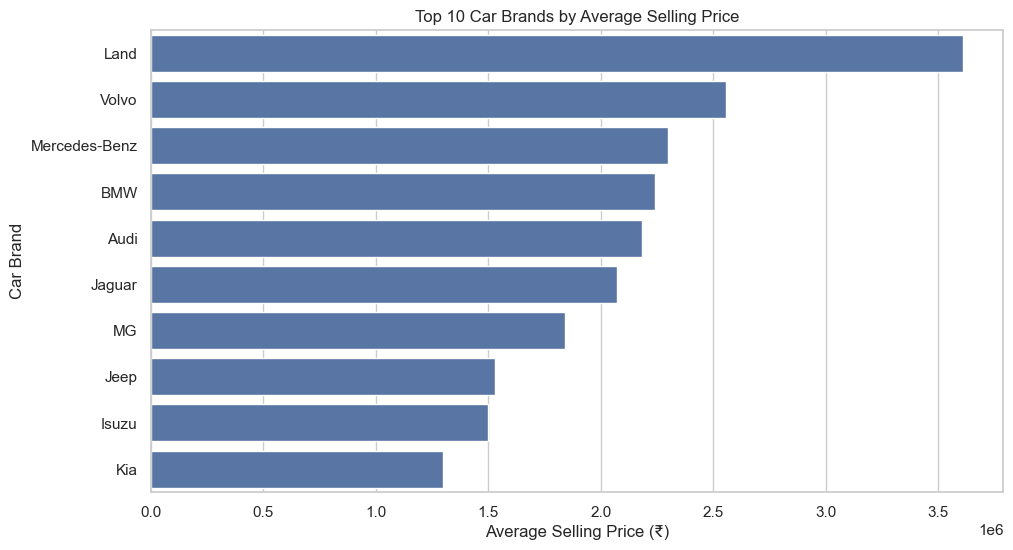

In [33]:
brand_price = (
    df.groupby("brand")["selling_price"]
    .mean()
    .sort_values(ascending=False)
)

print("TOP 10 BRANDS BY AVERAGE SELLING PRICE")
print(brand_price.head(10).round(2))

plt.figure(figsize=(11, 6))

sns.barplot(
    x=brand_price.head(10).values,
    y=brand_price.head(10).index
)

plt.title("Top 10 Car Brands by Average Selling Price")
plt.xlabel("Average Selling Price (₹)")
plt.ylabel("Car Brand")

plt.savefig("images/08_brand_vs_price.png", bbox_inches="tight")
plt.show()

### Observation – Average Selling Price by Car Brand

1. Land has the highest average selling price of approximately ₹36.10 lakh.
2. Volvo ranks second, followed by Mercedes-Benz.
3. BMW, Audi, and Jaguar also have relatively high average selling prices.
4. Premium car brands generally show higher average prices in this dataset.
5. Brand-wise averages should be interpreted carefully because the number of records differs across brands.

NUMERICAL FEATURE CORRELATION:
               selling_price  km_driven  year  car_age
selling_price           1.00      -0.19  0.42    -0.42
km_driven              -0.19       1.00 -0.42     0.42
year                    0.42      -0.42  1.00    -1.00
car_age                -0.42       0.42 -1.00     1.00


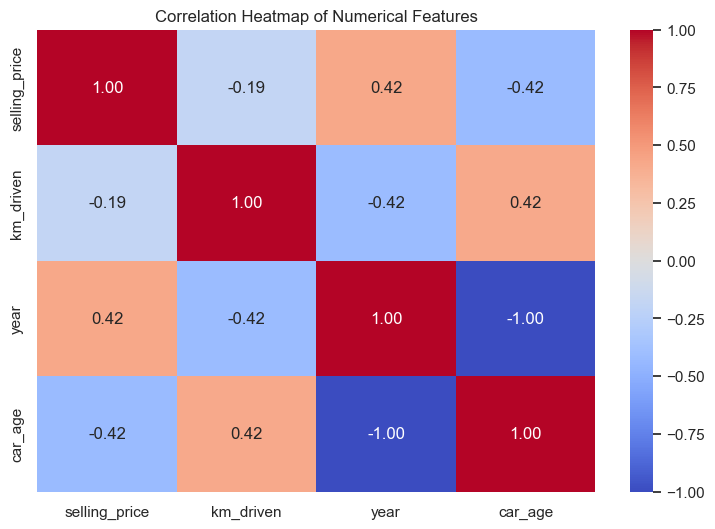

In [34]:
numeric_columns = [
    "selling_price",
    "km_driven",
    "year",
    "car_age"
]

correlation_matrix = df[numeric_columns].corr()

print("NUMERICAL FEATURE CORRELATION:")
print(correlation_matrix.round(2))

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.savefig("images/09_correlation_heatmap.png", bbox_inches="tight")
plt.show()
plt.show()

### Observation – Numerical Feature Correlation

1. Selling price has a moderate positive correlation with manufacturing year (0.42).
2. Selling price has a moderate negative correlation with car age (-0.42).
3. Kilometres driven has a weak negative correlation with selling price (-0.19).
4. Manufacturing year and car age have a perfect negative correlation (-1.00).
5. For machine learning, car age will be used instead of both year and car age to avoid redundant features.

In [35]:
# Select features for machine learning
X = df[
    [
        "car_age",
        "km_driven",
        "fuel",
        "seller_type",
        "transmission",
        "owner",
        "brand"
    ]
]

# Select target variable
y = df["selling_price"]

print("FEATURES SHAPE:", X.shape)
print("TARGET SHAPE:", y.shape)

print("\nFEATURE COLUMNS:")
print(X.columns.tolist())

print("\nTARGET SAMPLE:")
print(y.head())

FEATURES SHAPE: (3577, 7)
TARGET SHAPE: (3577,)

FEATURE COLUMNS:
['car_age', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'brand']

TARGET SAMPLE:
0     60000
1    135000
2    600000
3    250000
4    450000
Name: selling_price, dtype: int64


In [36]:
# Convert categorical columns into numerical columns
X_encoded = pd.get_dummies(
    X,
    columns=[
        "fuel",
        "seller_type",
        "transmission",
        "owner",
        "brand"
    ],
    drop_first=True,
    dtype=int
)

print("ORIGINAL FEATURES SHAPE:", X.shape)
print("ENCODED FEATURES SHAPE:", X_encoded.shape)

print("\nFIRST 5 ENCODED ROWS:")
print(X_encoded.head())

print("\nDATA TYPES:")
print(X_encoded.dtypes.value_counts())

ORIGINAL FEATURES SHAPE: (3577, 7)
ENCODED FEATURES SHAPE: (3577, 41)

FIRST 5 ENCODED ROWS:
   car_age  km_driven  fuel_Diesel  fuel_Electric  fuel_LPG  fuel_Petrol  \
0       19      70000            0              0         0            1   
1       19      50000            0              0         0            1   
2       14     100000            1              0         0            0   
3        9      46000            0              0         0            1   
4       12     141000            1              0         0            0   

   seller_type_Individual  seller_type_Trustmark Dealer  transmission_Manual  \
0                       1                             0                    1   
1                       1                             0                    1   
2                       1                             0                    1   
3                       1                             0                    1   
4                       1                         

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

print("TRAINING DATA SHAPE:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTESTING DATA SHAPE:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTOTAL RECORDS:", len(X_train) + len(X_test))

TRAINING DATA SHAPE:
X_train: (2861, 41)
y_train: (2861,)

TESTING DATA SHAPE:
X_test: (716, 41)
y_test: (716,)

TOTAL RECORDS: 3577


In [38]:
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [39]:
# Predict car prices using the testing data
y_pred_lr = lr_model.predict(X_test)

print("LINEAR REGRESSION PREDICTIONS")
print("\nActual Prices:")
print(y_test.head(10).values)

print("\nPredicted Prices:")
print(y_pred_lr[:10].round(2))

LINEAR REGRESSION PREDICTIONS

Actual Prices:
[ 270000  525000  990000 3800000  229999  325000  210000  500000  790000
  360000]

Predicted Prices:
[ 527597.75  470512.27  954225.67 2035903.77  142904.54  376689.61
  168008.35  530721.49  801828.67  418051.82]


In [40]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Calculate evaluation metrics
mae_lr = mean_absolute_error(y_test, y_pred_lr)

rmse_lr = np.sqrt(
    mean_squared_error(y_test, y_pred_lr)
)

r2_lr = r2_score(y_test, y_pred_lr)

print("LINEAR REGRESSION MODEL EVALUATION")
print("----------------------------------")
print("MAE:", round(mae_lr, 2))
print("RMSE:", round(rmse_lr, 2))
print("R2 Score:", round(r2_lr, 4))

LINEAR REGRESSION MODEL EVALUATION
----------------------------------
MAE: 180194.99
RMSE: 385606.09
R2 Score: 0.5384


In [41]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [42]:
# Predict car prices using Random Forest
y_pred_rf = rf_model.predict(X_test)

print("RANDOM FOREST PREDICTIONS")

print("\nActual Prices:")
print(y_test.head(10).values)

print("\nPredicted Prices:")
print(y_pred_rf[:10].round(2))

RANDOM FOREST PREDICTIONS

Actual Prices:
[ 270000  525000  990000 3800000  229999  325000  210000  500000  790000
  360000]

Predicted Prices:
[ 578831.65  471080.41 1470089.91 2626919.16  242766.66  350413.54
  185458.33  665156.76  881663.41  472520.  ]


In [43]:
# Calculate Random Forest evaluation metrics

mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("RANDOM FOREST MODEL EVALUATION")
print("----------------------------------")
print("MAE:", round(mae_rf, 2))
print("RMSE:", round(rmse_rf, 2))
print("R2 Score:", round(r2_rf, 4))

RANDOM FOREST MODEL EVALUATION
----------------------------------
MAE: 157505.36
RMSE: 361448.67
R2 Score: 0.5944


In [44]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae_lr, mae_rf],
    "RMSE": [rmse_lr, rmse_rf],
    "R2 Score": [r2_lr, r2_rf]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,180194.987022,385606.086098,0.538415
1,Random Forest,157505.362100,361448.665620,0.594438


In [45]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
8,transmission_Manual,2.475776e-01
0,car_age,2.224354e-01
1,km_driven,1.380812e-01
2,fuel_Diesel,6.549153e-02
5,fuel_Petrol,5.036716e-02
13,brand_Audi,4.843450e-02
27,brand_Land,4.022919e-02
38,brand_Toyota,3.725869e-02
6,seller_type_Individual,1.973209e-02
14,brand_BMW,1.471349e-02


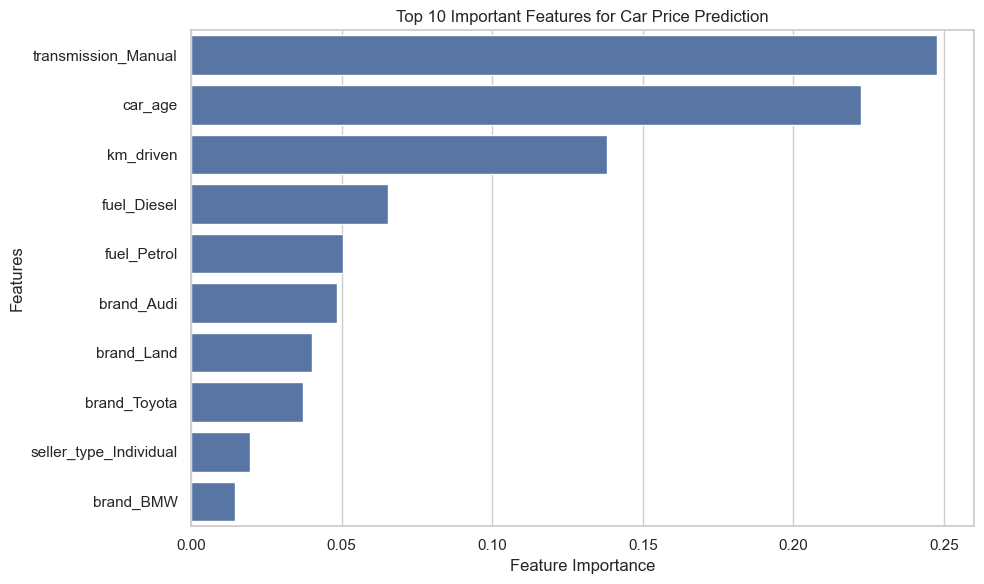

In [46]:
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(10)

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features for Car Price Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()

plt.savefig(
    "images/10_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Final Observations and Conclusion

### Key Findings

1. The dataset contains 4,340 original records. After removing duplicate records, 3,577 records remained.
2. Car age has a negative relationship with selling price. Older cars generally have lower selling prices.
3. Kilometres driven also has a negative relationship with selling price.
4. Transmission type, car age, and kilometres driven were among the most important features identified by the Random Forest model.
5. The Random Forest Regressor performed better than Linear Regression on all three evaluation metrics.

### Model Performance

- **Linear Regression:** MAE = ₹180,194.99, RMSE = ₹385,606.09, R² = 0.5384
- **Random Forest:** MAE = ₹157,505.36, RMSE = ₹361,448.67, R² = 0.5944

### Conclusion

In this project, I performed exploratory data analysis and built machine learning models to predict used car selling prices. I trained and evaluated Linear Regression and Random Forest Regression models.

The Random Forest model achieved better results, with an R² score of 0.5944. Therefore, it was selected as the better-performing model for this dataset.

This project helped me understand data cleaning, feature engineering, categorical encoding, regression modelling, model evaluation, and feature importance analysis.